# Expirement running multiple ASP programs multiple times to get mean grounding/solving times

### Loading puzzles

In [1]:
import clingo
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import time
from concurrent.futures import ThreadPoolExecutor
import sys
import importlib

def load_program(puzzle, gen, configuration, base_rules, puzzle_path):
    '''
        Load the necessary lp files to load a complete puzzle:
        - with base file
        - with puzzle world
        - with clues
        and create a clingo control variable
    '''
    ctl = clingo.Control(["0", "--stats=2", "--warn=no-atom-undefined", f"--configuration={configuration}"])
    ctl.load('../solve-experiment.lp')
    ctl.load(f'../{base_rules}')
    if gen:
        ctl.load(f'../autogenerated_puzzles/puzzles/puzzle{puzzle}.lp')
        ctl.load(f'../autogenerated_puzzles/clues/clues{puzzle}.lp')
    else:
        ctl.load(f'{puzzle_path}/puzzle{puzzle}.lp')
        ctl.load(f'../clues/clues{puzzle}.lp')
    ground_start = time.perf_counter()
    ctl.ground([("base", [])])
    ground_time = time.perf_counter() - ground_start
    grounded_at = sum(1 for atom in ctl.symbolic_atoms.by_signature('at', 3)) # grounded placements for people at certain locations
    return ctl, ground_time, grounded_at
 
def solve_puzzle(puzzle, gen=False, count=False, configuration='auto', base_rules='base-rules.lp', debug=False, puzzle_path='../puzzles'):
    '''
        Solve a clingo program by loading an lp file.
        Output atoms
        Output all solutions
    '''
    # models_with_atoms = []
    ctl, ground_time, grounded_at = load_program(puzzle, gen, configuration, base_rules, puzzle_path)
    def on_model(model):
        # models_with_atoms.append(model.symbols(atoms=True))
        if debug:
            print(model.symbols(shown=True))
        else:
            pass
    with ctl.solve(on_model=on_model, yield_=True) as handle:
        models = list(handle)
        result = handle.get()
        stats = ctl.statistics
        solve_time = stats['summary']['times']['solve']
        grid_size = ctl.get_const('n').number

        # extract number of clues:
        atoms = ctl.symbolic_atoms
        clue_count = sum(1 for atom in atoms if atom.symbol.name == 'clue')

        #extract the types of clues:
        all_clue_types = ['in_same_room', 'not_in_same_room', 'next_to', 'not_next_to', 'on', 'in', \
                    'in_top_row', 'in_bottom_row', 'in_left_column', 'in_right_column', 'alone', 'not_alone', 'not_in',  'in_corner', 'not_in_corner', 'no_empty_room', \
                    'in_room_with_female', 'not_in_room_with_female', 'in_room_with_male', 'not_in_room_with_male', 'not_on', 'only_one_on',  'n_persons_on', 'in_room_with_multiple_females', 'in_room_with_multiple_males', \
                    'east_of', 'west_of', 'north_of', 'south_of', 'next_to_with_someone_else', 'object_in_col', 'no_object_in_col', 'object_in_row', 'no_object_in_row', \
                    'in_column', 'in_row', 'n_east_of', 'n_west_of', 'n_north_of', 'n_south_of', 'someone_else_in_room_on', 'someone_else_in_room_next_to', 'object_in_same_room']
        clue_type_counts = {}
        for atom in atoms:
            if atom.symbol.name == 'clue':
                args = [str(arg) for arg in atom.symbol.arguments]
                for arg in args:
                    if arg in all_clue_types:
                        clue_type_counts[arg] = clue_type_counts.setdefault(arg, 0) + 1

    if count:
        print(f'Number of models: {len(models)}')
        
    if debug:
        print(result)
        print("Satisfiable:", result.satisfiable)
        print("Unsatisfiable:", result.unsatisfiable)
        print("Unknown:", result.unknown)
    return result, ground_time, solve_time, grid_size, clue_count, clue_type_counts, models, grounded_at
# , models_with_atoms

#### Store results

In [2]:
def store_result(results, epoch, puzzle, type, ground_time, solve_time, total_time, grid_size, clue_count, clue_type_counts, solve_state, num_solutions, choice_type, grounded_at, constraint_type):
    results.append({
        'epoch': epoch, # epoch
        'puzzle': puzzle, # puzzle number
        'type': type, # automated puzzles with 'type': 'A' manual with 'M', comes from file names.
        'ground_time': ground_time, # time spent on grounding all possibilities
        'solve_time': solve_time, # time spent on solving all grounded rules
        'total_time': total_time, # total time
        'grid_size': grid_size, # grid size of puzzle X*X
        'clue_count': clue_count, # number of clues
        'clue_type_counts': clue_type_counts, # dictionary with types of clues
        'solve_state': solve_state, # is puzzle satisfiable
        'num_solutions': num_solutions, # number of solutions, should always be 1
        'choice_type': choice_type, # normal
        'grounded_at': grounded_at, # add number of grounded at/3 predicates
        'constraint_type': constraint_type # type of constraint for unique row and col
    })

#### Small experiment with dynamic choice rules vs normal choice rules
```ASP
# const n=6.
suspect(1, alphonse).
suspect(2, bonnie).
suspect(3, carol).
suspect(4, daniel).
suspect(5,emily).
victim(6,victor).

row(R) :- R = 0..n.
col(C) :- C = 0..n. 
step(T) :- T = 1..n+1.

{assign(P,R,C,T) : row(R), col(C), not occupied_row(R,T), not occupied_col(C,T), can_occupy(R,C)} = 1 :- person(T,P).

occupied_row(R,T) :- step(T), assign(_,R,_,T0), T0 < T.
occupied_col(C,T) :- step(T), assign(_,_,C,T0), T0 < T.

at(P,R,C) :- assign(P,R,C,T).
```

#### Small experiment between normal constraints and aggregate constraints
```ASP
:- person(P1), person(P2), at(P1,R1,C1), at(P2,R2,C2), R1=R2, P1!=P2.
:- person(P1), person(P2), at(P1,R1,C1), at(P2,R2,C2), C1=C2, P1!=P2.
```

VS

```ASP
:- at(_,_,C), #count{P : at(P,R,C)} != 1.
:- at(_,R,_), #count{P : at(P,R,C)} != 1.
```

In [24]:
epochs=5
puzzles = list(Path('../puzzles_dynamic').glob("puzzle*.lp"))
results_choice_agg = []

for i in range(epochs):
    print(f'start epoch {i+1}/{epochs}')

    for p in puzzles:
        puzzle_id = p.stem.removeprefix("puzzle")
        puzzle_type = puzzle_id[0]
        puzzle_num = int(puzzle_id.split('-')[1])
        print(f'Puzzle #{puzzle_id}, {puzzle_type}, {puzzle_type == 'A'}')
        result, ground_time, solve_time, grid_size, clue_count, clue_type_counts, models, grounded_at = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules.lp')
        result_dyn, ground_time_dyn, solve_time_dyn, grid_size_dyn, clue_count_dyn, clue_type_counts_dyn, models_dyn, grounded_at_dyn = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules-dyn.lp', puzzle_path='../puzzles_dynamic')
        result_agg, ground_time_agg, solve_time_agg, grid_size_agg, clue_count_agg, clue_type_counts_agg, models_agg, grounded_at_agg = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules-agg.lp')

        store_result(results_choice_agg, i, puzzle_num, puzzle_type, ground_time, solve_time, ground_time + solve_time, grid_size + 1, clue_count, clue_type_counts, result.satisfiable, len(models), 'ASP', grounded_at, 'Normal')
        store_result(results_choice_agg, i, puzzle_num, puzzle_type, ground_time_dyn, solve_time_dyn, ground_time_dyn + solve_time_dyn, grid_size_dyn + 1, clue_count_dyn, clue_type_counts_dyn, result_dyn.satisfiable, len(models_dyn), 'Dynamic Choice', grounded_at_dyn, 'Normal')
        store_result(results_choice_agg, i, puzzle_num, puzzle_type, ground_time_agg, solve_time_agg, ground_time_agg + solve_time_agg, grid_size_agg + 1, clue_count_agg, clue_type_counts_agg, result_agg.satisfiable, len(models_agg), 'Agg Constraint', grounded_at_agg, 'Aggregate')
    print(f'end epoch {i+1}/{epochs}')
    print()
    print('----------------------------------')
    print()

start epoch 1/5
Puzzle #M9-30, M, False
Puzzle #M9-55, M, False
Puzzle #M9-45, M, False
Puzzle #M6-1, M, False
Puzzle #M8-10, M, False
Puzzle #M8-24, M, False
Puzzle #M6-21, M, False
Puzzle #M6-2, M, False
Puzzle #M9-28, M, False
Puzzle #M7-8, M, False
Puzzle #M9-27, M, False
end epoch 1/5

----------------------------------

start epoch 2/5
Puzzle #M9-30, M, False
Puzzle #M9-55, M, False
Puzzle #M9-45, M, False
Puzzle #M6-1, M, False
Puzzle #M8-10, M, False
Puzzle #M8-24, M, False
Puzzle #M6-21, M, False
Puzzle #M6-2, M, False
Puzzle #M9-28, M, False
Puzzle #M7-8, M, False
Puzzle #M9-27, M, False
end epoch 2/5

----------------------------------

start epoch 3/5
Puzzle #M9-30, M, False
Puzzle #M9-55, M, False
Puzzle #M9-45, M, False
Puzzle #M6-1, M, False
Puzzle #M8-10, M, False
Puzzle #M8-24, M, False
Puzzle #M6-21, M, False
Puzzle #M6-2, M, False
Puzzle #M9-28, M, False
Puzzle #M7-8, M, False
Puzzle #M9-27, M, False
end epoch 3/5

----------------------------------

start epoch 4/5


In [25]:
# put results in pandas frame
df_choice_agg= pd.DataFrame(results_choice_agg)
df_choice_agg.head()

,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,clue_type_counts,solve_state,num_solutions,choice_type,grounded_at,constraint_type
0,0,30,M,0.167598,0.042143,0.209741,9,10,"{'next_to': 3, 'in': 1, 'not_in': 1, 'only_one...",True,1,ASP,549,Normal
1,0,30,M,0.129586,0.040119,0.169705,9,10,"{'next_to': 3, 'in': 1, 'not_in': 1, 'only_one...",True,1,Dynamic Choice,549,Normal
2,0,30,M,0.133251,0.016476,0.149727,9,10,"{'next_to': 3, 'in': 1, 'not_in': 1, 'only_one...",True,1,Agg Constraint,549,Aggregate
3,0,55,M,0.151395,0.091983,0.243378,9,14,"{'on': 2, 'in_same_room': 1, 'in_room_with_mul...",True,1,ASP,540,Normal
4,0,55,M,0.134806,0.171638,0.306444,9,14,"{'on': 2, 'in_same_room': 1, 'in_room_with_mul...",True,1,Dynamic Choice,540,Normal


In [26]:
# check for failed solutions or multiple solutions
failed = df_choice_agg[df_choice_agg['solve_state'] == False]
len(failed)

0

In [27]:
# check for failed solutions or multiple (or no) solutions
wrong_sol = df_choice_agg[df_choice_agg['num_solutions'] != 1]
len(wrong_sol)

0

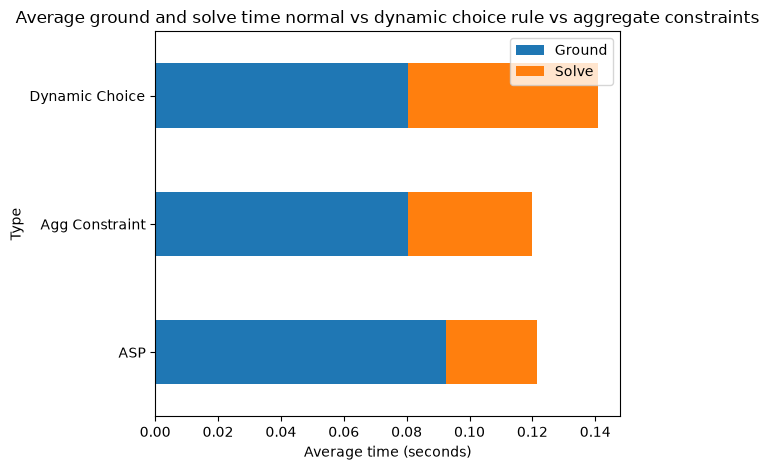

In [28]:
# compare number of ground predicates for at/3 in resulting grounded program
df_choice_agg.groupby('choice_type')[['ground_time','solve_time']].mean().plot(kind='barh', stacked=True)

plt.title('Average ground and solve time normal vs dynamic choice rule vs aggregate constraints')
plt.ylabel('Type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve'])
plt.tight_layout()
plt.show()

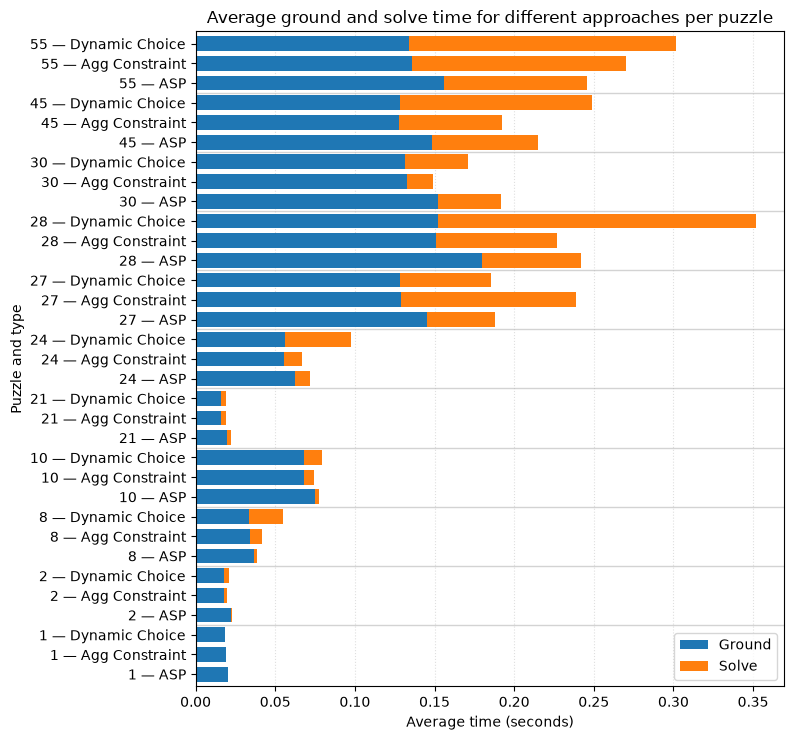

In [29]:
# compare number of ground predicates for at/3 in resulting grounded program
df_plot = (
    df_choice_agg
    .groupby(['puzzle', 'choice_type'])[['ground_time', 'solve_time']]
    .mean()
    .sort_index()
)

ax = df_plot.plot(kind='barh', stacked=True, width=0.75, figsize=(8, 7.5))

plt.title('Average ground and solve time for different approaches per puzzle')
plt.ylabel('Puzzle and type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve'], loc='lower right')
plt.tight_layout()

# Draw separators after every three bars
n_results = 3
for y in np.arange(n_results - 0.5, len(df_plot) - 0.5, n_results):
    ax.axhline(y=y, color='lightgray', linewidth=1, zorder=0)

ax.set_yticks(
    np.arange(len(df_plot)),
    [f'{puzzle} — {choice_type}' for puzzle, choice_type in df_plot.index]
)

# Keep gridlines behind the bars
ax.set_axisbelow(True)
ax.xaxis.grid(True, linestyle=':', alpha=0.4)

plt.show()

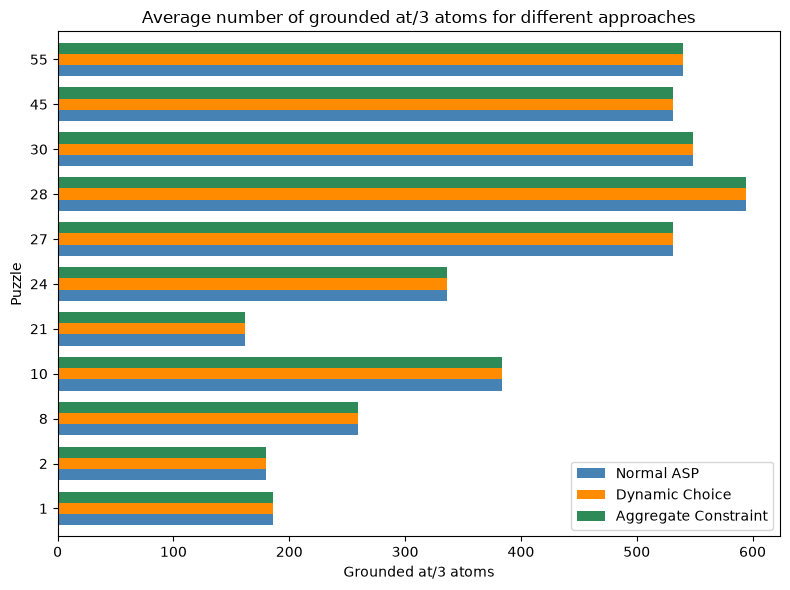

In [637]:
# compare ground_time/solve_time/total_time for both approaches
df_choice_agg.groupby(['puzzle','choice_type'])[['grounded_at']].mean().unstack('choice_type').plot(
    kind='barh', color=['steelblue', 'darkorange', 'seagreen'], width=0.75, figsize=(8,6)
)

plt.title('Average number of grounded at/3 atoms for different approaches')
plt.ylabel('Puzzle')
plt.xlabel('Grounded at/3 atoms')
plt.legend(['Normal ASP', 'Dynamic Choice', 'Aggregate Constraint'])
plt.tight_layout()
plt.show()

## Run main experiment
- epoch is one run of all available puzzles
- type 'M' puzzles are manually taken from Murdoku book 1
- type 'A' puzzles are automatically generated with our Murdoku-generator
- statistics like grounding time, solving time, total time, grid size and number of clues are stored per puzzle per epoch, these can later be used for analysis
- Python vs ASP vs ASP with aggregate constraints


In [5]:
# Reload the module after it has been updated
project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root))

import solver.pythonsolver as pythonsolver


importlib.reload(pythonsolver)


<module 'solver.pythonsolver' from '/Users/jurgen/Code/MASTER_OU/MBAI/project/murdoku-solve/solver/pythonsolver.py'>

### Original run (non parallel).
For parallel solving (3 approaches per puzzle), see below

In [ ]:
# number of runs for experiment
epochs = 3
debug = False

puzzles = list(Path('../puzzles').glob("puzzle*.lp"))
puzzles_gen = list(Path('../autogenerated_puzzles/puzzles').glob('puzzle*.lp'))
puzzles.extend(puzzles_gen)
results = []
for i in range(epochs):
    if debug:
        print(f'start epoch {i+1}/{epochs}')

    for ip, p in enumerate(puzzles):
        puzzle_id = p.stem.removeprefix("puzzle")
        puzzle_type = puzzle_id[0]
        puzzle_num = int(puzzle_id.split('-')[1])
        grid_size_from_file_name = int(puzzle_id.split('-')[0][1:])
        if debug:
            print(f'Puzzle #{puzzle_id}, {puzzle_type}, {puzzle_type == 'A'}')

        # run both ASP implementations
        result, ground_time, solve_time, grid_size, clue_count, clue_type_counts, models, grounded_at = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules.lp')
        result_agg, ground_time_agg, solve_time_agg, grid_size_agg, clue_count_agg, clue_type_counts_agg, models_agg, grounded_at_agg = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules-agg.lp')

        # run python solver:                
        puzzle_base_path = '..' if puzzle_type == 'M' else '../autogenerated_puzzles'
        pfile = f'{puzzle_base_path}/puzzles/puzzle{puzzle_type}{grid_size_from_file_name}-{puzzle_num}.lp'
        cfile = f'{puzzle_base_path}/clues/clues{puzzle_type}{grid_size_from_file_name}-{puzzle_num}.lp'
        n_sol_python, interpret_time_python, solve_time_python, solutions_python, n_clues_python, clue_type_counts_python = pythonsolver.find_solutions(pfile, cfile)

        # store results for 3 methods:
        store_result(results, i, puzzle_num, puzzle_type, ground_time, solve_time, ground_time + solve_time, grid_size + 1, clue_count, clue_type_counts, result.satisfiable, len(models), 'ASP', grounded_at, 'Normal')
        store_result(results, i, puzzle_num, puzzle_type, ground_time_agg, solve_time_agg, ground_time_agg + solve_time_agg, grid_size + 1, clue_count, clue_type_counts_agg, result_agg.satisfiable, len(models_agg), 'ASP', grounded_at_agg, 'Aggregate')
        store_result(results, i, puzzle_num, puzzle_type, interpret_time_python, solve_time_python, interpret_time_python + solve_time_python, grid_size_from_file_name, n_clues_python, clue_type_counts_python, n_sol_python>0, n_sol_python, 'Python', None, 'Python')

        if ip > 0 and ip % 50 == 0:
            print(f'epoch {i+1}/{epochs} at {ip}/{len(puzzles)} puzzles')

    print(f'end epoch {i+1}/{epochs}')
    print()
    print('----------------------------------')
    print()

start epoch 1/1
Puzzle #M9-30, M, False
Puzzle #M9-55, M, False
Puzzle #M9-45, M, False
Puzzle #M6-1, M, False
Puzzle #M8-10, M, False
Puzzle #M8-24, M, False
Puzzle #M6-21, M, False
Puzzle #M6-2, M, False
Puzzle #M9-28, M, False
Puzzle #M7-8, M, False
Puzzle #M9-27, M, False
Puzzle #A6-69, A, True
Puzzle #A13-58, A, True
Puzzle #A7-94, A, True
Puzzle #A5-80, A, True
Puzzle #A9-97, A, True
Puzzle #A6-38, A, True
Puzzle #A9-64, A, True
Puzzle #A10-42, A, True
Puzzle #A8-99, A, True
Puzzle #A5-73, A, True
Puzzle #A7-36, A, True
Puzzle #A10-13, A, True
Puzzle #A9-35, A, True
Puzzle #A5-22, A, True
Puzzle #A7-67, A, True
Puzzle #A12-56, A, True
Puzzle #A10-9, A, True
Puzzle #A11-78, A, True
Puzzle #A4-49, A, True
Puzzle #A10-85, A, True
Puzzle #A12-91, A, True
Puzzle #A11-29, A, True
Puzzle #A4-18, A, True
Puzzle #A7-53, A, True
Puzzle #A12-62, A, True
Puzzle #A6-8, A, True
Puzzle #A10-27, A, True
Puzzle #A5-16, A, True
Puzzle #A12-33, A, True
Puzzle #A10-76, A, True
Puzzle #A9-50, A, True

KeyboardInterrupt: 

### Parallel uitvoeren van verschillende methodes per puzzle

In [3]:
def run_task(task):
    puzzle_id, puzzle_type, grid_size, approach = task

    if approach == "ASP":
        return solve_puzzle(
            puzzle_id,
            puzzle_type == 'A',
            configuration='auto',
            base_rules='base-rules.lp'
        )

    elif approach == "AGG":
        return solve_puzzle(
            puzzle_id,
            puzzle_type == 'A',
            configuration='auto',
            base_rules='base-rules-agg.lp'
        )

    elif approach == "Python":
        puzzle_base_path = '..' if puzzle_type == 'M' else '../autogenerated_puzzles'
        pfile = f'{puzzle_base_path}/puzzles/puzzle{puzzle_type}{grid_size}-{puzzle_num}.lp'
        cfile = f'{puzzle_base_path}/clues/clues{puzzle_type}{grid_size}-{puzzle_num}.lp'
        return pythonsolver.find_solutions(pfile, cfile)

In [7]:
epochs = 5
debug = False

puzzles = list(Path('../puzzles').glob("puzzle*.lp"))
puzzles_gen = list(Path('../autogenerated_puzzles/puzzles').glob('puzzle*.lp'))
puzzles.extend(puzzles_gen)
results_par = []

executor = ThreadPoolExecutor(max_workers=3)

for i in range(epochs):
    start_epoch = time.perf_counter()
    start_batch = time.perf_counter()
    if debug:
        print(f'start epoch {i+1}/{epochs}')

    for ip, p in enumerate(puzzles):
        puzzle_id = p.stem.removeprefix("puzzle")
        puzzle_type = puzzle_id[0]
        puzzle_num = int(puzzle_id.split('-')[1])
        grid_size_from_file_name = int(puzzle_id.split('-')[0][1:])

        # create tasks for parallel processing
        tasks = [
            (puzzle_id, puzzle_type, grid_size_from_file_name, 'ASP'),
            (puzzle_id, puzzle_type, grid_size_from_file_name, 'AGG'),
            (puzzle_id, puzzle_type, grid_size_from_file_name, 'Python')
        ]

        futures = [executor.submit(run_task, task) for task in tasks]
        result_set = [future.result() for future in futures]

        result, ground_time, solve_time, grid_size, clue_count, clue_type_counts, models, grounded_at = result_set[0]
        result_agg, ground_time_agg, solve_time_agg, grid_size_agg, clue_count_agg, clue_type_counts_agg, models_agg, grounded_at_agg = result_set[1]
        n_sol_python, interpret_time_python, solve_time_python, solutions_python, n_clues_python, clue_type_counts_python = result_set[2]

        # store results
        store_result(results_par, i, puzzle_num, puzzle_type, ground_time, solve_time, ground_time + solve_time, grid_size + 1, clue_count, clue_type_counts, result.satisfiable, len(models), 'ASP', grounded_at, 'ASP')
        store_result(results_par, i, puzzle_num, puzzle_type, ground_time_agg, solve_time_agg, ground_time_agg + solve_time_agg, grid_size + 1, clue_count_agg, clue_type_counts_agg, result_agg.satisfiable, len(models_agg), 'ASP', grounded_at_agg, 'Aggregate constraints')
        store_result(results_par, i, puzzle_num, puzzle_type, interpret_time_python, solve_time_python, interpret_time_python + solve_time_python, grid_size_from_file_name, n_clues_python, clue_type_counts_python, n_sol_python>0, n_sol_python, 'Python', None, 'Python')

        if ip > 0 and ip % 50 == 0:
            elapsed_batch = time.perf_counter() - start_batch
            print(f'epoch {i+1}/{epochs} at {ip}/{len(puzzles)} puzzles')
            print(f"Elapsed batch time: {elapsed_batch:.2f} seconds")
            start_batch = time.perf_counter()

    elapsed_epoch = time.perf_counter() - start_epoch
    print(f'end epoch {i+1}/{epochs}')
    print(f"Elapsed epoch time: {elapsed_epoch:.2f} seconds")
    print()
    print('----------------------------------')
    print()
executor.shutdown()

epoch 1/5 at 50/1111 puzzles
Elapsed batch time: 353.29 seconds
epoch 1/5 at 100/1111 puzzles
Elapsed batch time: 250.99 seconds
epoch 1/5 at 150/1111 puzzles
Elapsed batch time: 466.50 seconds
epoch 1/5 at 200/1111 puzzles
Elapsed batch time: 426.35 seconds
epoch 1/5 at 250/1111 puzzles
Elapsed batch time: 105.77 seconds
epoch 1/5 at 300/1111 puzzles
Elapsed batch time: 531.87 seconds
epoch 1/5 at 350/1111 puzzles
Elapsed batch time: 250.92 seconds
epoch 1/5 at 400/1111 puzzles
Elapsed batch time: 396.20 seconds
epoch 1/5 at 450/1111 puzzles
Elapsed batch time: 282.20 seconds
epoch 1/5 at 500/1111 puzzles
Elapsed batch time: 172.94 seconds
epoch 1/5 at 550/1111 puzzles
Elapsed batch time: 196.85 seconds
epoch 1/5 at 600/1111 puzzles
Elapsed batch time: 346.02 seconds
epoch 1/5 at 650/1111 puzzles
Elapsed batch time: 219.78 seconds
epoch 1/5 at 700/1111 puzzles
Elapsed batch time: 219.94 seconds
epoch 1/5 at 750/1111 puzzles
Elapsed batch time: 206.76 seconds
epoch 1/5 at 800/1111 puzz

### Analyze
- convert results to Pandas DataFrame for easy evaluation

#### Error checks
- check for unsatisfiable puzzles
- check for puzzles with multiple solutions

#### Compare results
- Compare results between approaches
- Compare performance between puzzles (commented out)
- Compare performance between grid sizes
- Compare performance between number of clues
- Compare performance between generated and manual puzzles
- Compare performance between combination of grid size and number of clues
- Compare performance between combination of grid size and generated/manual

In [8]:
df = pd.DataFrame(results_par)
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 16665 entries, 0 to 16664
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   epoch             16665 non-null  int64  
 1   puzzle            16665 non-null  int64  
 2   type              16665 non-null  str    
 3   ground_time       16665 non-null  float64
 4   solve_time        16665 non-null  float64
 5   total_time        16665 non-null  float64
 6   grid_size         16665 non-null  int64  
 7   clue_count        16665 non-null  int64  
 8   clue_type_counts  16665 non-null  object 
 9   solve_state       16665 non-null  bool   
 10  num_solutions     16665 non-null  int64  
 11  choice_type       16665 non-null  str    
 12  grounded_at       11110 non-null  float64
 13  constraint_type   16665 non-null  str    
dtypes: bool(1), float64(4), int64(5), object(1), str(3)
memory usage: 1.7+ MB


,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,clue_type_counts,solve_state,num_solutions,choice_type,grounded_at,constraint_type
0,0,30,M,0.193572,0.045745,0.239317,9,10,"{'next_to': 3, 'in': 1, 'not_in': 1, 'only_one...",True,1,ASP,549.0,ASP
1,0,30,M,0.173450,0.021591,0.195041,9,10,"{'next_to': 3, 'in': 1, 'not_in': 1, 'only_one...",True,1,ASP,549.0,Aggregate constraints
2,0,30,M,0.000921,0.003823,0.004744,9,10,"{'next_to': 3, 'alone': 1, 'in': 1, 'not_in': ...",True,1,Python,NaN,Python
3,0,55,M,0.183775,0.121270,0.305045,9,14,"{'on': 2, 'in_same_room': 1, 'in_room_with_mul...",True,1,ASP,540.0,ASP
4,0,55,M,0.162330,0.180148,0.342478,9,14,"{'on': 2, 'in_same_room': 1, 'in_room_with_mul...",True,1,ASP,540.0,Aggregate constraints


In [9]:
df.to_csv('main-results-2.csv', index=False)

In [ ]:
df = pd.read_csv('main-results-2.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16665 entries, 0 to 16664
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   epoch             16665 non-null  int64  
 1   puzzle            16665 non-null  int64  
 2   type              16665 non-null  str    
 3   ground_time       16665 non-null  float64
 4   solve_time        16665 non-null  float64
 5   total_time        16665 non-null  float64
 6   grid_size         16665 non-null  int64  
 7   clue_count        16665 non-null  int64  
 8   clue_type_counts  16665 non-null  str    
 9   solve_state       16665 non-null  bool   
 10  num_solutions     16665 non-null  int64  
 11  choice_type       16665 non-null  str    
 12  grounded_at       11110 non-null  float64
 13  constraint_type   16665 non-null  str    
dtypes: bool(1), float64(4), int64(5), str(4)
memory usage: 1.7 MB


In [10]:
(~df['solve_state']).sum()

np.int64(0)

In [11]:
# check for puzzles with multiple solutions
multi_solutions = df[(df['num_solutions'] > 1) & (df['epoch'] == 0)]
multi_solutions

,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,clue_type_counts,solve_state,num_solutions,choice_type,grounded_at,constraint_type


In [12]:
# Check whether each puzzle is solved once per epoch per method
df.groupby(['epoch','puzzle', 'type', 'grid_size', 'constraint_type']).size().sort_values(ascending=False)

epoch  puzzle  type  grid_size  constraint_type      
0      1       A     4          ASP                      1
3      33      A     10         ASP                      1
                                Python                   1
                     11         ASP                      1
                                Aggregate constraints    1
                                                        ..
1      67      A     9          Aggregate constraints    1
                                Python                   1
                     10         ASP                      1
                                Aggregate constraints    1
4      100     A     14         Python                   1
Length: 16665, dtype: int64

In [13]:
# get average times per method
df.groupby('constraint_type')[['ground_time','solve_time','total_time']].mean()

,ground_time,solve_time,total_time
constraint_type,,,
ASP,0.918556,3.368694,4.287249
Aggregate constraints,0.804075,3.425220,4.229295
Python,0.002928,0.769727,0.772654


constraint_type       ASP  Aggregate constraints    Python
type                                                      
A                4.328599               4.270066  0.694123
M                0.152263               0.152190  8.625837


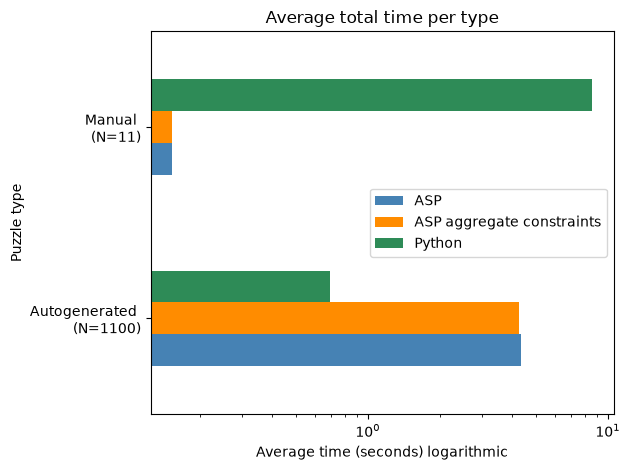

In [14]:
# average ground/solve/total times per method
df_grouped = df.groupby(['type', 'constraint_type'])['total_time'].mean().unstack('constraint_type')
print(df_grouped)
ax = df_grouped.plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)

labels = {'M': 'Manual \n(N=11)','A': 'Autogenerated \n(N=1100)'}

ax.set_xscale('log')
plt.ylabel('Puzzle type')
plt.xlabel('Average time (seconds) logarithmic')
plt.yticks(
    ticks=range(len(df_grouped.index)),
    labels=[labels[x] for x in df_grouped.index]
)
plt.title('Average total time per type')
plt.legend(['ASP', 'ASP aggregate constraints', 'Python'])
plt.tight_layout()
plt.show()

In [15]:
# get mean scores per puzzle per method and find longest total time
df.groupby(['puzzle', 'type', 'grid_size', 'constraint_type'])[
    ['ground_time', 'solve_time', 'total_time', 'grounded_at']
].mean().sort_values('total_time', ascending=False).head(30)

ground_time  solve_time  \
puzzle type grid_size constraint_type                                  
85     A    14        Aggregate constraints     3.626689  243.468398   
                      ASP                       4.191788  208.455012   
98     A    14        Aggregate constraints     3.408738  112.612105   
                      ASP                       3.874994  110.738053   
90     A    14        Aggregate constraints     3.520139  106.800295   
28     M    9         Python                    0.002345   91.663081   
90     A    14        ASP                       4.051214   80.244238   
72     A    14        ASP                       4.285602   74.332192   
69     A    14        Aggregate constraints     3.480045   63.763379   
80     A    14        ASP                       4.173595   59.190865   
34     A    14        ASP                       3.927485   55.308965   
80     A    14        Aggregate constraints     3.661002   54.468735   
94     A    14        Aggregate constraints     3.220379   50.277472   
49     A    14        ASP                       4.268793   47.961772   
41     A    14        Aggregate constraints     3.362778   47.063703   
44     A    13        Aggregate constraints     2.355359   48.030919   
94     A    14        ASP                       3.682107   44.411990   
95     A    14        Aggregate constraints     3.739742   43.103798   
18     A    14        ASP                       4.120190   42.228298   
12     A    14        Aggregate constraints     3.637801   42.482538   
95     A    14        ASP                       4.287912   41.650796   
52     A    13        ASP                       2.608958   43.239523   
12     A    14        ASP                       4.154454   39.699254   
10     A    14        ASP                       4.488875   38.915150   
92     A    14        Aggregate constraints     3.725336   39.424646   
38     A    14        ASP                       4.718939   37.447108   
17     A    14        ASP                       3.878097   38.140800   
39     A    14        Aggregate constraints     4.036148   37.904816   
9      A    14        ASP                       4.091985   37.683180   
10     A    14        Aggregate constraints     3.855193   37.857510   

                                             total_time  grounded_at  
puzzle type grid_size constraint_type                                 
85     A    14        Aggregate constraints  247.095086       2296.0  
                      ASP                    212.646800       2296.0  
98     A    14        Aggregate constraints  116.020844       2254.0  
                      ASP                    114.613048       2254.0  
90     A    14        Aggregate constraints  110.320434       2254.0  
28     M    9         Python                  91.665425          NaN  
90     A    14        ASP                     84.295453       2254.0  
72     A    14        ASP                     78.617794       2366.0  
69     A    14        Aggregate constraints   67.243425       2268.0  
80     A    14        ASP                     63.364460       2338.0  
34     A    14        ASP                     59.236449       2296.0  
80     A    14        Aggregate constraints   58.129737       2338.0  
94     A    14        Aggregate constraints   53.497850       2184.0  
49     A    14        ASP                     52.230566       2366.0  
41     A    14        Aggregate constraints   50.426482       2254.0  
44     A    13        Aggregate constraints   50.386277       1859.0  
94     A    14        ASP                     48.094097       2184.0  
95     A    14        Aggregate constraints   46.843540       2366.0  
18     A    14        ASP                     46.348488       2338.0  
12     A    14        Aggregate constraints   46.120340       2338.0  
95     A    14        ASP                     45.938709       2366.0  
52     A    13        ASP                     45.848481       1872.0  
12     A    14        ASP           

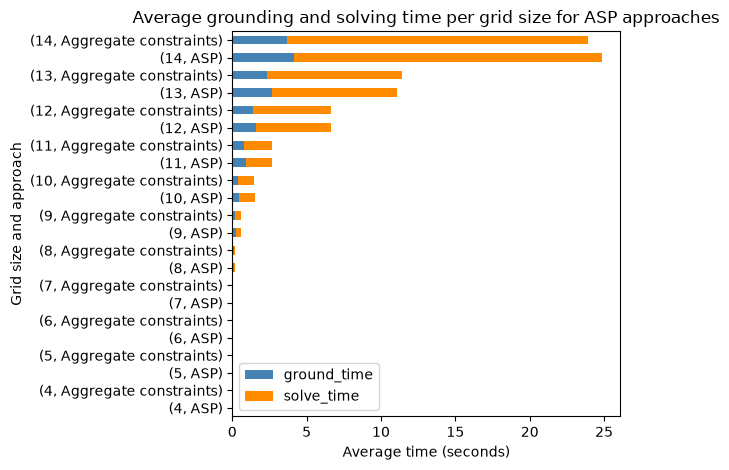

In [16]:
# Compare average ground/solve times ASP per grid size
df_asp = df[df['constraint_type'] != 'Python']

ax = df_asp.groupby(['grid_size', 'constraint_type'])[
    ['ground_time', 'solve_time']
].mean().plot(
    kind='barh',
    stacked=True,
    color=['steelblue', 'darkorange']
)

plt.ylabel('Grid size and approach')
plt.xlabel('Average time (seconds)')
plt.title('Average grounding and solving time per grid size for ASP approaches')
plt.tight_layout()
plt.show()

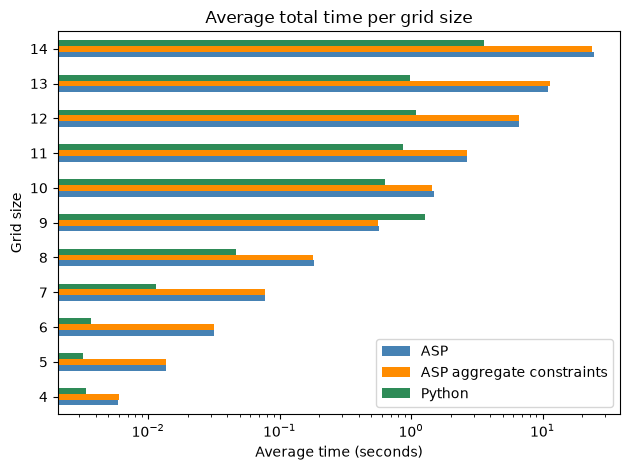

In [17]:
# Compare average total time spend per grid size between methods
ax = df.groupby(['grid_size', 'constraint_type'])['total_time'].mean().unstack('constraint_type').plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)
ax.set_xscale('log')
plt.ylabel('Grid size')
plt.xlabel('Average time (seconds)')
plt.title('Average total time per grid size')
plt.legend(['ASP', 'ASP aggregate constraints', 'Python'], loc='lower right')
plt.tight_layout()
plt.show()

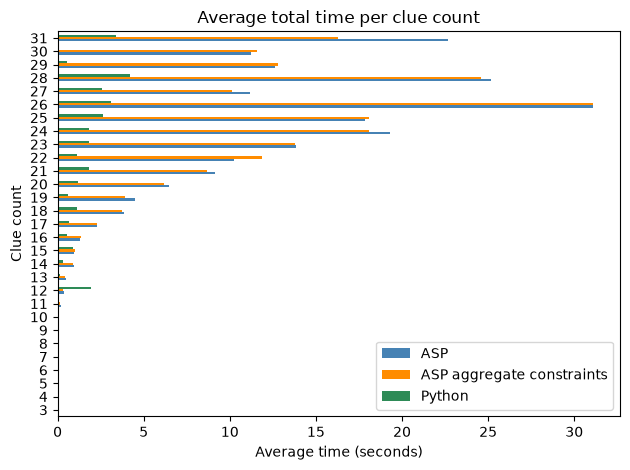

In [18]:
# Compare average total time spend per clue size between methods
ax = df.groupby(['clue_count', 'constraint_type'])['total_time'].mean().unstack('constraint_type').plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)

plt.ylabel('Clue count')
plt.xlabel('Average time (seconds)')
plt.title('Average total time per clue count')
plt.legend(['ASP', 'ASP aggregate constraints', 'Python'], loc='lower right')
plt.tight_layout()
plt.show()

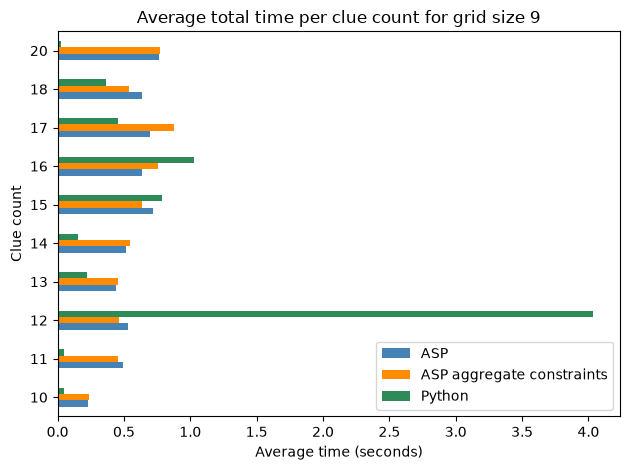

In [19]:
# One interesting combination seems to be clue count = 12 and grid size = 9
# Compare average total time spend per clue size for grid size = 9 between methods
df_grid_size_9 = df[df['grid_size'] == 9]

ax = df_grid_size_9.groupby(['clue_count', 'constraint_type'])['total_time'].mean().unstack('constraint_type').plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)

plt.ylabel('Clue count')
plt.xlabel('Average time (seconds)')
plt.title('Average total time per clue count for grid size 9')
plt.legend(['ASP', 'ASP aggregate constraints', 'Python'], loc='lower right')
plt.tight_layout()
plt.show()

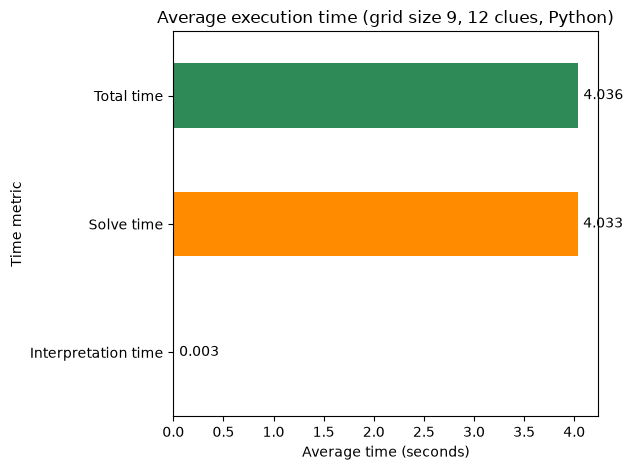

In [20]:
# One interesting combination seems to be clue count = 12 and grid size = 9
# Compare average ground/solve/total time spend
df_grid_size_9_clue_size_12_python = df[(df['grid_size'] == 9) & (df['clue_count'] == 12) & (df['constraint_type'] == 'Python')]

times = df_grid_size_9_clue_size_12_python[['ground_time','solve_time','total_time']].mean()
times.index = ['Interpretation time', 'Solve time', 'Total time']

ax = times.plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)
ax.bar_label(ax.containers[0], fmt='%.3f', padding=4)

ax.set_ylabel('Time metric')
ax.set_xlabel('Average time (seconds)')
ax.set_title('Average execution time (grid size 9, 12 clues, Python)')
plt.tight_layout()
plt.show()

In [21]:
# Must be solving time then, it is because of Manual input puzzle 28 which has 90 seconds of solving time. Inspect?
df_grid_size_9_clue_size_12_python.head(100) 

,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,clue_type_counts,solve_state,num_solutions,choice_type,grounded_at,constraint_type
8,0,45,M,0.002769,3.160255,3.163024,9,12,"{'in': 1, 'east_of': 1, 'south_of': 1, 'next_t...",True,1,Python,NaN,Python
26,0,28,M,0.002753,91.462107,91.464860,9,12,"{'only_one_on': 1, 'someone_else_in_room_next_...",True,1,Python,NaN,Python
71,0,35,A,0.003256,0.033452,0.036708,9,12,"{'n_persons_on': 1, 'someone_else_in_room_next...",True,1,Python,NaN,Python
125,0,50,A,0.002774,0.062662,0.065436,9,12,"{'only_one_on': 1, 'in': 2, 'not_alone': 1, 'i...",True,1,Python,NaN,Python
161,0,40,A,0.000488,0.007979,0.008467,9,12,"{'in_same_room': 1, 'not_next_to': 2, 'no_obje...",True,1,Python,NaN,Python
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13319,3,16,A,0.000252,0.027141,0.027393,9,12,"{'no_object_in_row': 1, 'in': 1, 'next_to': 1,...",True,1,Python,NaN,Python
13340,4,45,M,0.000261,3.017016,3.017277,9,12,"{'in': 1, 'east_of': 1, 'south_of': 1, 'next_t...",True,1,Python,NaN,Python
13358,4,28,M,0.000229,91.691559,91.691788,9,12,"{'only_one_on': 1, 'someone_else_in_room_next_...",True,1,Python,NaN,Python
13403,4,35,A,0.000294,0.033329,0.033623,9,12,"{'n_persons_on': 1, 'someone_else_in_room_next...",True,1,Python,NaN,Python


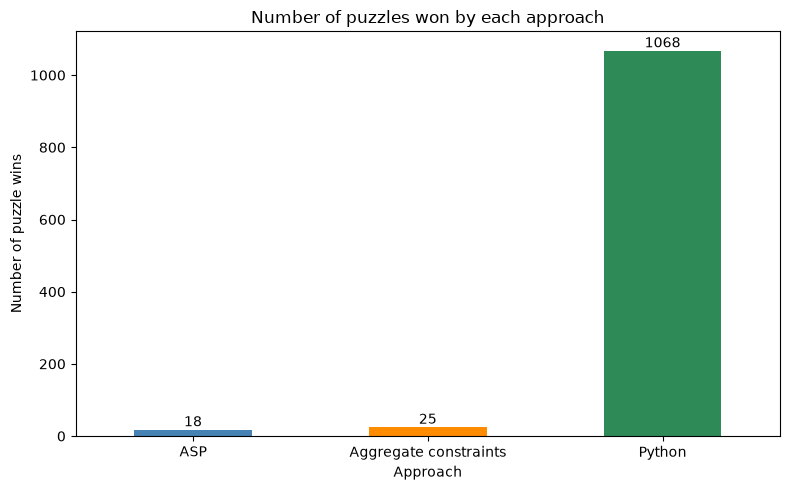

In [22]:
# Compare winner based on total time spent per puzzle averages
avg_total_times = df.groupby(['puzzle','type','grid_size','constraint_type'])['total_time'].mean().unstack('constraint_type')
winners = avg_total_times.idxmin(axis=1)
win_counts = winners.value_counts().reindex(avg_total_times.columns, fill_value=0)

colors = {
    'ASP': 'steelblue',
    'Aggregate constraints': 'darkorange',
    'Python': 'seagreen'
}

ax = win_counts.plot(
    kind='bar',
    color=[colors[t] for t in win_counts.index],
    figsize=(8, 5)
)

ax.set_xlabel('Approach')
ax.set_ylabel('Number of puzzle wins')
ax.set_title('Number of puzzles won by each approach')
ax.bar_label(ax.containers[0], fmt='%d')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

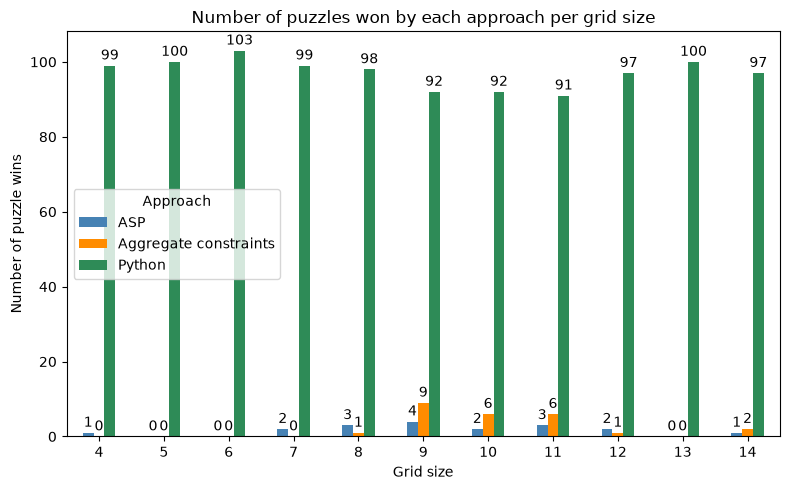

In [23]:
# Compare winner based on total time spent per puzzle averages (divided per grid?)
avg_total_times = df.groupby(['puzzle','type','grid_size','constraint_type'])['total_time'].mean().unstack('constraint_type')
winners = avg_total_times.idxmin(axis=1).rename('winner')
winner_df = winners.reset_index()

win_counts = (
    winner_df.groupby(['grid_size', 'winner']).size().unstack('winner', fill_value=0)
)

approaches = ['ASP', 'Aggregate constraints', 'Python']
win_counts = win_counts.reindex(columns=approaches, fill_value=0)

colors = {
    'ASP': 'steelblue',
    'Aggregate constraints': 'darkorange',
    'Python': 'seagreen'
}

ax = win_counts.plot(
    kind='bar',
    color=[colors[t] for t in win_counts.columns],
    figsize=(8, 5)
)

ax.set_xlabel('Grid size')
ax.set_ylabel('Number of puzzle wins')
ax.set_title('Number of puzzles won by each approach per grid size')
ax.bar_label(ax.containers[0], fmt='%d', padding=2)
ax.bar_label(ax.containers[1], fmt='%d', padding=2)
ax.bar_label(ax.containers[2], fmt='%d', padding=2)
plt.xticks(rotation=0)
plt.legend(title='Approach')
plt.tight_layout()
plt.show()

#### Who was the most frequent killer across the puzzle set?

In [636]:
df.head()

,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,clue_type_counts,solve_state,num_solutions,choice_type,grounded_at,constraint_type
0,0,30,M,0.214804,0.058140,0.272944,9,10,"{'next_to': 3, 'in': 1, 'not_in': 1, 'only_one...",True,1,ASP,549.0,ASP
1,0,30,M,0.196502,0.032160,0.228662,9,10,"{'next_to': 3, 'in': 1, 'not_in': 1, 'only_one...",True,1,ASP,549.0,Aggregate constraints
2,0,30,M,0.000882,0.005607,0.006489,9,10,"{'next_to': 3, 'alone': 1, 'in': 1, 'not_in': ...",True,1,Python,NaN,Python
3,0,55,M,0.219541,0.123824,0.343365,9,14,"{'on': 2, 'in_same_room': 1, 'in_room_with_mul...",True,1,ASP,540.0,ASP
4,0,55,M,0.196225,0.168083,0.364309,9,14,"{'on': 2, 'in_same_room': 1, 'in_room_with_mul...",True,1,ASP,540.0,Aggregate constraints


In [241]:
df.groupby('grid_size')[['ground_time', 'solve_time', 'total_time']].mean()

,ground_time,solve_time,total_time
grid_size,,,
4,0.003783,0.000329,0.004112
5,0.009235,0.001381,0.010616
6,0.021491,0.003923,0.025414
7,0.046995,0.014286,0.061282
8,0.096156,0.051067,0.147223
9,0.191893,0.135699,0.327592
10,0.361391,0.591928,0.953319
11,0.645106,2.302929,2.948034


In [ ]:
epochs = 1
debug = False

puzzles = list(Path('../puzzles').glob("puzzle*.lp"))
puzzles_gen = list(Path('../autogenerated_puzzles/puzzles').glob('puzzle*.lp'))
puzzles.extend(puzzles_gen)
murderers = {}
suspect_counts = {}
for i in range(epochs):
    start_epoch = time.perf_counter()
    start_batch = time.perf_counter()
    if debug:
        print(f'start epoch {i+1}/{epochs}')

    for ip, p in enumerate(puzzles):
        puzzle_id = p.stem.removeprefix("puzzle")
        puzzle_type = puzzle_id[0]
        puzzle_num = int(puzzle_id.split('-')[1])

        result, ground_time, solve_time, grid_size, clue_count, clue_type_counts, models, grounded_at, models_with_atoms = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules.lp')

        # store results
        murderer = next(
            (atom.arguments[0].name for atom in models_with_atoms[0]
            if atom.name == 'murderer'),
            None
        )
        suspects = [
            atom.arguments[0].name for atom in models_with_atoms[0]
            if atom.name == 'suspect'
        ]
        for suspect in suspects:
            suspect_counts[suspect] = suspect_counts.setdefault(suspect, 0) + 1
        murderers[murderer] = murderers.setdefault(murderer, 0) + 1
        if ip > 0 and ip % 50 == 0:
            elapsed_batch = time.perf_counter() - start_batch
            print(f'epoch {i+1}/{epochs} at {ip}/{len(puzzles)} puzzles')
            print(f"Elapsed batch time: {elapsed_batch:.2f} seconds")
            start_batch = time.perf_counter()

    elapsed_epoch = time.perf_counter() - start_epoch
    print(f'end epoch {i+1}/{epochs}')
    print(f"Elapsed epoch time: {elapsed_epoch:.2f} seconds")
    print()
    print('----------------------------------')
    print()

# print(murderers, suspect_counts)
murder_scores = {murderer : count / suspect_counts[murderer] for murderer, count in murderers.items() if suspect_counts.get(murderer, 0) > 0 }
# print(murder_scores)



## Murderer statistics
As the following analysis of murder statistics suggest, Ivan and Jesse might not be as thrustworthy as one might think 😉

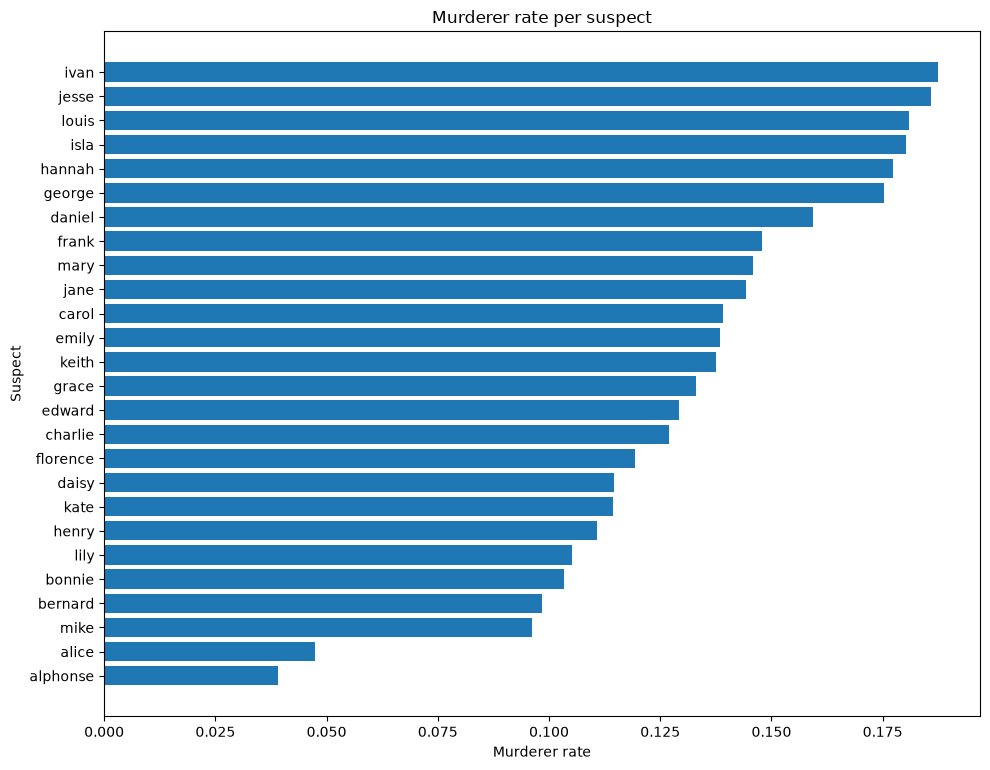

In [18]:
import matplotlib.pyplot as plt

scores_sorted = dict(sorted(murder_scores.items(), key=lambda x: x[1]))

plt.figure(figsize=(10, max(5, len(scores_sorted) * 0.3)))
plt.barh(list(scores_sorted.keys()), list(scores_sorted.values()))

plt.xlabel('Murderer rate')
plt.ylabel('Suspect')
plt.title('Murderer rate per suspect')
plt.tight_layout()
plt.show()